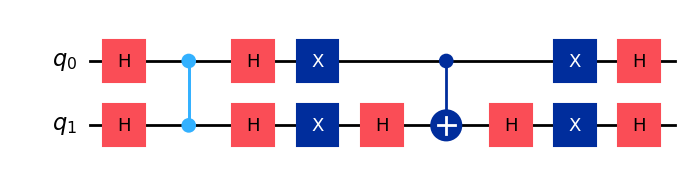

In [7]:
from qiskit import QuantumCircuit
import matplotlib.pyplot as plt

qc = QuantumCircuit(2)

qc.h(0)
qc.h(1)
qc.cz(0, 1)
qc.h(0)
qc.h(1)
qc.x(0)
qc.x(1)

#Same as applying CZ gate
qc.h(1)
qc.cx(0, 1)
qc.h(1)
qc.barrier()

qc.x(0)
qc.x(1)
qc.h(0)
qc.h(1)

fig = qc.draw(output="mpl", plot_barriers=False)
display(fig)
plt.close(fig)

In [3]:
from qiskit.quantum_info import Statevector

# Statevector simulation
statevector = Statevector(qc)
print(statevector)

Statevector([ 0.+0.j,  0.+0.j,  0.+0.j, -1.+0.j],
            dims=(2, 2))


In [4]:
from qiskit.providers.basic_provider import BasicProvider

# Basic simulation
qc.measure_all()

backend = BasicProvider().get_backend("basic_simulator")
result = backend.run(qc).result()

print(result.get_counts())

{'11': 1024}


In [9]:
from qiskit.qasm2 import dump

# Save the circuit to a qasm file
with open("qc2.qasm", "w") as f:
    dump(qc, f)